In [1]:
_TRUSTDESC_LOCAL_WORKSPACE = '/Users/macbramesha/Documents/Codex/2026-11-09/https-github-com-samarthramesha-trustdesc-reproduction-2/work/notebook-fresh'

# TRUSTDESC · Local research reproduction
**Apple Silicon primary · free local inference · evidence and checkpoint recovery**

Open in local Jupyter and choose **Run All**. This notebook contains its own hash-checked implementation, creates a project-local Python environment, installs pinned dependencies, tests Python startup, qualifies a real model, executes SliceMin → DescGen → DynVer, compares Original / lite / full with a fixed task agent, and packages the recorded evidence. No uploads, API keys or manual cell edits are required. First use downloads public packages and model weights.

The paper is [Ye et al., TRUSTDESC, arXiv:2604.07536v1](https://arxiv.org/abs/2604.07536v1). Its original 52-tool/208-task release remains unauthenticated/unavailable. The automatic comparison uses eight explicitly authored tasks and two pure tools; these results are not the paper's TSR. Public source analysis has separate provenance. A finished software run or handover does not establish full scientific reproduction.

Apple Silicon uses quantized MLX when installed, otherwise supported MPS or CPU. Model selection considers available memory and must pass real inference, JSON-structure and action checks. No generation is replaced by scripted answers. Optional Colab notebooks remain under `notebooks/colab/`.

## 1 · Recover the exact source
Source is embedded in this notebook and checked against SHA-256 before import. Cached files are rechecked. The runtime is stored in `trustdesc_local` beside the notebook; old runs are preserved. The notebook never needs to download a moving Git branch.

In [2]:
import base64, hashlib, io, json, os, platform, shutil, signal, subprocess, sys, time, venv, zipfile
from pathlib import Path, PurePosixPath
from IPython.display import display, Markdown, FileLink, SVG
BASE = Path(globals().get("_TRUSTDESC_LOCAL_WORKSPACE", "trustdesc_local")).resolve()
BASE.mkdir(parents=True, exist_ok=True)
SOURCE_HASHES = {'LICENSE': '153de023e3ae1a344dbd2ea57c003f3e5f1de56a04ddcdd62c9a8f8718efcb56', 'NOTICE.md': '972d5b1158f43e165380a5b702cf0204fcb79fe1b0a7a8f8e447b46b443d0f1a', 'PROJECT_STATE.md': 'c60a26c64f0780d23b1831a34bc8ecb601a713900f192e2e96ef8fc0b7228984', 'README.md': '13ae56f6bec0c2aa1228f124f6c817ba49225006abdf285586fc4914de481ba8', 'configs/colab_experiment.json': 'd62e9db19bcf232157eeb58634a649aa7a7c6d0ba5b95cb65aa4308a66d93c6e', 'configs/colab_models.json': '67ee505ec61e8c990afa5ad3b31f591703843cc83000467d9ae9d9f7c2c7b4e9', 'configs/default.json': 'f3f1a79b3682a5ccfb91889b997c898c8f6436acfc807f7454264a721c66ba52', 'configs/experiments.json': '4f8ad204a8a06964589a07ccfa1cbffd6aad2b3ce42d8001a6e940c497fb99a4', 'configs/models.json': '0ce09cda2b1b7d44ea0e2563fd5cd7fc0b13ea9937d76642be8ab99082542eaf', 'configs/original_benchmark_contract.json': '315bf32365db842a9d15de2a60ed66cfd40eb319165952b4ff9bc95d3be38a46', 'configs/reproduction.json': '5231a5f5a0a7078a9a6d694463fd08cde7975fec95f7e8f1e98fdbbd257f8fb1', 'configs/reproduction_resources.json': 'e045aa32bae3fbd1279dd497c4244f633fe3af0bcefa16c84845b75707b0542c', 'configs/small_model.json': '82b0b74e57e53bd009b0be70db0a592f93b4482770e1cbe2874ae4ce5bcdc41d', 'data/manifests/acquired_sources.json': 'a0af02ac5c83b0e4184a80fc6320e1cd4353b3a5a80fda9a0f4e42af077fe4d1', 'data/manifests/paper_attacks.json': '9008117a10915235d7608426d2cee994c66c10a6059e54600d8fe3a8ddb9d204', 'data/manifests/paper_fingerprint.json': 'deb836fccab4f9d2ed27a21e394e69fcaefd1bb45255a911ec53406e44e817d5', 'data/manifests/paper_servers.json': 'da10ff31937b55b010abb3e32c64980e0142d245a053ceb54f8f6db4f6408b5b', 'data/manifests/public_example.json': 'f35a4dd6a02a2fdb12e4eff06cfb03225bdbaad2850bae8686f23a9b12875791', 'data/public_example/LICENSE': '5e13dbbc1d120fc2a03cecde7c91424ae2d7de11b63d58ded2f4431e261ee50d', 'data/public_example/server.py': '96f3a8692eff290dba9e68a788956f58893a72426a7a78539c3cae4b9ed65a02', 'docs/ARCHITECTURE.md': '402eb053e450300ab3a5ec2098ced78b3877cd3067ad23cb7cd25a9817f8400b', 'docs/COLAB_EXPERIMENT_GUIDE.md': 'eee413211aab0bcad57d2a11e8967813297c9ee36e0547071d129b2e059da34a', 'docs/COLAB_HANDOVER.md': '79d523dfd4cc03900600fd5dfdd416e04b54f3706b32dd0fb13d85066eccf0e2', 'docs/DATASET_ANALYSIS.md': '64fdf17e60f205a6f40b5d8191e101bf618e9018e6697a32c0636ebc23843d52', 'docs/EVIDENCE_LEDGER.md': '123281339dd3ea34efc06ba893603c1f17de9353380dec9c2f2787cdef977881', 'docs/EXPERIMENT_LOG.md': '14714045ae5609337abf31b7e4e929039a224b3dc766b06d2e9ba1d1a7dfc88c', 'docs/FRESH_ENVIRONMENT_SETUP.md': 'c291f20f4de8f9eab8dab33f6c800b9d30e6ab0dc93b30ee46a66ca959b84d21', 'docs/GITHUB_PUBLICATION.md': '0d00c7ed4de7cca83124fcbd0683b91ece81f700e0f30bf4646ac2b391bfe416', 'docs/HISTORICAL_README_PHASE1.md': 'd52feef8c70202608022bb555ca01b5e5792b49f98616e9341005dd5d6c7047f', 'docs/IMPLEMENTATION_AUDIT_2026_11_09.md': '36b93a28d37b0718ffb39c0213c095618a82a278b1eccfea0a7cc6129f6ac8b8', 'docs/IMPLEMENTATION_DECISIONS.md': '0440eb3af5ec899a3c1a865bb4161134fbd5758d18c233f542558c12f0d16802', 'docs/LIMITATIONS.md': '86b8ca0bedfbf4d67ffa38b9e85d32bb29a0139390c791d65883ac57bd6d6f6d', 'docs/METHODOLOGY.md': '41e62c4baeb8a3a3dd4dcdbd8ec332fa07ff57cb9ededbf5036e2a4179236b8f', 'docs/NEXT_STEPS.md': '8091e7e5ec91ef28bb72d0d7506f8bd894b7cd1db3316e8511047f8dbf964bec', 'docs/PAPER_ANALYSIS.md': 'd0c94428e053c1377429ccd997bfab8099afb6d96e0e30a846ee812a2f599d98', 'docs/PHASE1_COMPLETION_AUDIT.md': '6ddeb07c66c5492978b2718dde089bf6075dc9f25c3af5b5a0e7c750c1c57986', 'docs/PROJECT_HANDOVER.md': 'a30b4ae9e68b3ad05b4329046041d245ce24144a5be25647c5081a6efafe04c1', 'docs/PYTHON_STARTUP_INVESTIGATION.md': 'df8fb82929b575fd22fe465ba9017250eb66e0d53f4b58cd8b074e5b1fad989b', 'docs/RECOVERY_REPORT.md': 'f706d4816a4ef332d85755c67c4a3f76994c7c0ed5c7ce08e9f056d1efd6020a', 'docs/REPRODUCTION_STATUS.md': '3ec2b1b3a00cdef89bf4f0f821d31e5472d4b5d6bab294e1018fa448b23727d1', 'docs/REVIEW_PREPARATION.md': '97f13151dc46e0d3179f8c73f9dec1ff7b64230e9c82a774b185adbc23fcec6d', 'docs/SANDBOX.md': 'aea5ad1505f7b8bea3c3ff3ad3757a1907725ceade7073c9c40266b21c9ebb5e', 'docs/VALIDATION_AND_LIMITATIONS.md': '6abf890a03727cecf2c762dae8b60245f66d3a326cbfc602d11c5b990d579f53', 'pyproject.toml': '763ffd6604e8c7917c3fbc02f8914aee89e19cf8c97676e8dec0e3d46269bb91', 'reports/published_results.csv': '38cf3479d4f4e6d8b7793bec413f81d9b0cd0e3ed9f64cc6c0af0d34c9494324', 'requirements-apple-lock.txt': 'af223399a7d3ecd606742749d91d1beb323d81b03f3f53990e9a76cb3cbc2686', 'requirements-apple.txt': '753ba0366bffe83c063489c9ed5c531ce2ccf356e030b3856a1818208682fc78', 'requirements-colab.txt': 'dd1a61867da5212b0578b2e66ecc41cb80f05fc0bf762bf626dfc2be7c405606', 'requirements.txt': '808b9417e1abe78e8f7cc04556991004ac3850405a819380845861665d65422a', 'scripts/acquire_artifact.py': '27538c84d5685b36d0bd89661764b66fffa19206951f9ab5a37739dfaac58501', 'scripts/acquire_public_example.py': 'c6a3ded818254e5e0d990e8b559507b382b89f15cab7ce8821ae2003cad1c44c', 'scripts/audit_repository.py': '5cc4a0e4f6ee2714cc66b6a32b926f924b9554f19e0c8d52456e17ef349e787c', 'scripts/build_local_notebook.py': 'b18599d42a20e25237555436d0d4dfe260bb3797b0f624dc29e59e37e33c1b6a', 'scripts/build_reproduction_notebook.py': '31a2a41b2fd1026c7084b4e5a6e35a9ea712ff487dbd09453bcd87d7978cfc44', 'scripts/check_python_startup.py': '8a799707e03f55a26be1d93532ce45dffe92cff6fed279c371b0eefacac84021', 'scripts/discover_artifacts.py': '5ed6ed47c18edd2f8e0d550a8e660ffb493c8243628a3234a24daabe40fd8b88', 'scripts/package_project.py': '8b14c1a004c4630713ee55359e04424e2ae1dd4ed72eb713bd0fbff6f23973e6', 'scripts/prepare_dataset.py': '4a76e0fe0fd033fc3ba2bf94c61f7f9abe93698fbb9083b9c56a0aadd18a9b30', 'scripts/run_automatic_reproduction.py': '089f747ac56fc13c6ffa7d240b55b23687de223818395d5f9404e26393f39f06', 'scripts/run_colab_experiment.py': 'cbd5864b2d4e49c9e2bf14a4ba3dac3f2a16bbdcd136e2887e40552177191aec', 'scripts/run_descgen.py': 'fd3243ee9fa1c2e18458d97cba0b3914667b148ad275a61a95c101ce19d6de56', 'scripts/run_dynver.py': 'fc7dd32cc7edc1058656b96c74530663ef2e3c57014438ef7eba70c576ad6ed3', 'scripts/run_evaluation.py': 'cf06ecdd6e972e1865ce099c3ca9e16e1a309768ac02b74113c5f4f812ca5bb9', 'scripts/run_local_experiments.py': '4f2473498d00d0f239fe9b67a31e9c1fad16e815b8c83a99d104a9dc4e1f83b2', 'scripts/run_local_reproduction.py': '7513edbe30cb3e467a3de74b88d7564d9c0df9a6441c49fe51e6549e3635acaa', 'scripts/run_public_example.py': 'c98139e66205d3aed5471d930f8cbe79339e69be2d818c65468a9ee4b46a2303', 'scripts/run_public_static.py': '5c1e63a88c4908946e8bf3d5a867a0961e922fbe4c91b275985146da225443c9', 'scripts/run_slicemin.py': '597b6d6e7272ccfb15d82f9fe458898485717aa84fa3709b43f26668488a5888', 'scripts/run_small_model.py': '490f42a3e45eeaef4b1cceb1b5d6c2206a426ce1239fb270ced1507849e7fa63', 'scripts/run_tests.py': 'f0c7fb3cf6b50cc469d0d78aa44f1fff3fa2ed18b7b5519f839bbcfc4e73c1c2', 'scripts/validate_full_colab.py': '6483e72c41aadb8dbf984e97cf1f5c15074db0dfeb27dea956f6e4953c321a51', 'scripts/validate_local_notebook.py': '517beb5737d4e860eae87475aead23a79aa29941d7ef150ce79d15287160b9e1', 'scripts/validate_notebook.py': '554309180669278872fb554524f54cff836b7e86184527d6542bf8420dd7d1b3', 'scripts/validate_package.py': 'bd23563f6820fb8395cec997cfd40481f5785a0b6f8e734b2ee0a8f5a979c7a0', 'scripts/validate_reproduction_notebook.py': 'fa471f8dfb2653e803adbd37a684c3be1380df8c36263ffd087faff70c1f7593', 'src/trustdesc/__init__.py': '12d86d50a0571ce3ebd850078c61d98ac5c6d595d4f845908e9793d719a034a6', 'src/trustdesc/__main__.py': '935a1c1166b0c1ea35a82256345000bf2c73ded718d77773bc27a71ecce28f7d', 'src/trustdesc/cli.py': '37cb907db7389bdfc677af17d70ab9a903dd31046bfd4f1c4ae85ff463c45256', 'src/trustdesc/common/__init__.py': 'ba7bae2bfbda88212991e7c3f35716ed4709876571771a21563dbaad0d6f0009', 'src/trustdesc/common/io.py': 'f9d4a2b73dc2dd08c8c34c9f386bf90ce27c68ce27eb1ccf514ab319aa7ffadf', 'src/trustdesc/common/models.py': '8941f61941fdac08fa9e3e1284e38b19a234cf8bc7a32fc7a19a6e95bb946846', 'src/trustdesc/common/transformers_model.py': '60836358e7c53e80e3f697fa2c26de386fe340ce610a5b4b5d6eaaab4d75cee9', 'src/trustdesc/dataset/__init__.py': '369dd879f56e5ca7457e59a791ab21d67974868d8835b45e2e69d26c0b826966', 'src/trustdesc/dataset/acquire.py': 'c6aa11b974731556bf504d65ac34b327e5d3165a9b85e52e1ad6ae5a13cbee7b', 'src/trustdesc/dataset/prepare.py': '0cc36c0a6fd9646ed9ddb4cf0b6fcd4b7ff561fec34d4aa9a21fb5839ceebf0b', 'src/trustdesc/descgen/__init__.py': 'dd28014be8c22e087a0581ae20db1b12f459aa52431b8f1cde1b56aa0ad9c86d', 'src/trustdesc/descgen/generate.py': '81e453e7c466d8543f99ffdc98a55daa924eb491e5792b6c195427e7f47496a9', 'src/trustdesc/descgen/prompts.py': '3dc5d9c691a66ac00bbc07ad1bb017331cbff577ad603894ceae47e98f0d5dfa', 'src/trustdesc/descgen/sanitize.py': '6e73bb035b70b24e5e3bd167424932466ca992448516cb7271047c4a5dc39f53', 'src/trustdesc/dynver/__init__.py': '9988f6a69ef0949b6c2fd521d31b73c50d0a24a9840ab2ca1cbd1a66864cea0c', 'src/trustdesc/dynver/verify.py': 'f42cdc93e1488c905b480f9ee84234f08c3ab6459e5075aa2279a0a4ea0d8302', 'src/trustdesc/evaluation/__init__.py': '6d3183575a9cfce54ab63b0b05d8f4934b344d424bd385d69681152907c37cfb', 'src/trustdesc/evaluation/metrics.py': 'bcf97f6ce97cfc07cc3eca8b48ff11d6ea0eef95b50c8c0e60af86b64d525837', 'src/trustdesc/experiments/__init__.py': '7da7ee32c6909d71611fe766b63b53e134c963f8090c4e680db020264ace9f4c', 'src/trustdesc/experiments/data.py': 'faadd53b395ae5431e6589493cdc60abd2a101ae728d020d12e294fe1fd9586f', 'src/trustdesc/experiments/export.py': '5aaa76a15662df81d9f7f691bae35a2c856739d7fd12bea1471740de23c1752d', 'src/trustdesc/experiments/models.py': '1cd535d66bca99e1fae5d39bb380323fcf78f849ad0ce0dea110a20e58aafe08', 'src/trustdesc/experiments/report.py': '3c307c05a06c1f92f15411d403da2379dd896293d5aee23f641c08638329cbcc', 'src/trustdesc/experiments/review.py': 'a35982f1c86357b57900d246eb5dc8a53c199fde5198bf7f410eb13c999aa561', 'src/trustdesc/experiments/runtime.py': '52a8d89353566f8e01e4a191e7de41afefb456adb9566c822a662c2d86bf8dbc', 'src/trustdesc/experiments/setup.py': '166d43f1e6bc01f35f13c23ab5709244bad0e6b6ce20ec25eb5e6ee345af2885', 'src/trustdesc/experiments/storage.py': 'a19b8b546b1763fa02e333ce9f407330c952a41a880f6130d865825de0b3a645', 'src/trustdesc/experiments/workflow.py': 'e8ac248f4af86e3236ec551e19f7e0c6664dd0fde055eaa9d90ba0253c7c2e8a', 'src/trustdesc/fixtures.py': '10402c0c1895dc0944f19c8d74cbcf99f86184a7de9eb49cde4dd16d77e4b335', 'src/trustdesc/pipeline.py': 'e08fd52e16b31f6450801d13b7fd14cb709d4896fdab6dd239f255ac01750208', 'src/trustdesc/reproduction/__init__.py': '7885af062fda01ff1923032d657139cc51c340d914223e8cf486f65be6d7889f', 'src/trustdesc/reproduction/backends.py': '85e5d0639e8f39e9244730f6ad49085f534d59a085e3c34f4399cb8de1c927d2', 'src/trustdesc/reproduction/context.py': '58fa6b9efe2e6275f138fa0284435c9b2fdebf4232046a741d2a6e7edc17c117', 'src/trustdesc/reproduction/evidence.py': 'be2d7e4134945805d1006354587ddf2bb8d8551718f6006837435a3b92bb1ba2', 'src/trustdesc/reproduction/model.py': 'ca3b5196fd84282d3eeec861e90936263528e0c36acd2aa24213041cf7520873', 'src/trustdesc/reproduction/report.py': 'f47b5d26070a6750ba32ecb9c37c08a4077010514c2439596ddba685c3b72242', 'src/trustdesc/reproduction/resources.py': '34bb4a05b7974ee71b87eed1d8ba5acf3e2fb2be65b79d63f30df2f1ca042c60', 'src/trustdesc/reproduction/session.py': 'df0a8e4b2d2e79f84218bb0dd55e4192b81b6755e995810a542711af1608d376', 'src/trustdesc/reproduction/startup.py': '861055e5c48d8227e628a2cd9585460b64fa04cca449a1c557be998910cc5ca4', 'src/trustdesc/reproduction/workflow.py': '1e9a29100cf90811f11f7364ba9e44ebc6e5642fefd99d373c670362ea591b2f', 'src/trustdesc/resources/synthetic_server.py.txt': '0e168c22f203bab5472edc9d8efb716db4fdc64b0ab429e2e58b4c369ac5ce7d', 'src/trustdesc/sandbox/__init__.py': '14c551e9312a889668e374d6e48a50fe7269e0a2d5d086eb92ea7180670292e4', 'src/trustdesc/sandbox/fixture_tools.py': '1d9eef84be79d722b56bf4d14cfaba231d386a21c1d442475a27344ce498d725', 'src/trustdesc/sandbox/mcp_container.py': '5bc0a49694ac485c261ac61a1851c930aea8cd35b189d7c90dc1dc6448d97f85', 'src/trustdesc/sandbox/runner.py': 'c0ef49069e2f3027572ca58f5f9507e6f276b730b41bfd835ac75ea45b6fdfd5', 'src/trustdesc/sandbox/seatbelt.py': '260114f6a6cc4259b11eb6eddae6508bff74b7cdd271a06339bd4c2d502ff504', 'src/trustdesc/slicemin/__init__.py': '613cc2e63da63c44cef6fc5dff53a1ebdf5c0746a73efc34e4bedf047ba05cc6', 'src/trustdesc/slicemin/python.py': 'df368e9ca7ddd0ed0d722902cd5bd849694d8628594d1781d3817aa76c7c3777', 'src/trustdesc/slicemin/research.py': 'da033683c470391dd0158e285a3bc080b97ac12d1cca554cb3f8444b92cb30ea', 'tests/__init__.py': 'e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855', 'tests/fixtures/server.py': '0e168c22f203bab5472edc9d8efb716db4fdc64b0ab429e2e58b4c369ac5ce7d', 'tests/fixtures/tasks.jsonl': '0e3c872390d8eb12fcaac961dd32222db1447de6b68580c2e04d5f31bac22081', 'tests/integration/__init__.py': 'e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855', 'tests/integration/test_cli.py': 'bf7d54d9924a5b137bf2b366aa772f98cc9921988a18b039aa2e16cc2cd47095', 'tests/integration/test_pipeline.py': 'f14a0562daa9695df65acb8b90c0daac0b87b771dbcce86183444aea1153a802', 'tests/unit/__init__.py': 'e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855', 'tests/unit/test_colab_workflow.py': 'fd24ee2126679bf64e434346052d5015683fbfb8c49e1d7474670818ec0f4964', 'tests/unit/test_data_evaluation.py': '5d374c8f822da8795fa4702f0edd540e809147ef21e87298cbc62871a82fbaa4', 'tests/unit/test_descgen.py': '6bcf1da0b79bfe16e0a9c9ab11bc567b6917b69d84cc0ec0fd458c8b448cf72a', 'tests/unit/test_dynver.py': '1c3c07dd9a26dc326e6121f1692437598051c47001a044c508c4aa656dbbb22f', 'tests/unit/test_judge_evidence.py': 'b9683d3886eaaafbc2f3e5c7012814fed1f7ba79d54cf2249ca45d62f6a26bce', 'tests/unit/test_python_startup.py': '1d1cbcdd9bbc8dc802653cfae5e8dc35c28a78a1f2ed45ed130b91feff9e8a76', 'tests/unit/test_reproduction.py': '6006313593b9d9a79fc489cf40ee1714ead4026102f6e458d4212329d5b5e7d6', 'tests/unit/test_research_context.py': 'b014f9e7e4cd959283941d54ec537385ed6660148fddbe139049f57349d2cc75', 'tests/unit/test_slicemin.py': '8f641e5afa6f8b74eb83dd57c4cdc686bbe4db7620c38df6631520c1532611fc', 'tests/unit/test_source_context.py': '35e65e68ef33fb1e23f79bc8e975374f02413018ea03d225c1e9e3404018d9b2'}
SOURCE_ID = hashlib.sha256(json.dumps(SOURCE_HASHES,sort_keys=True).encode()).hexdigest()[:20]
PROJECT = BASE / ("source-" + SOURCE_ID)
EMBEDDED = '...'
with zipfile.ZipFile(io.BytesIO(base64.b64decode(EMBEDDED))) as archive:
    if set(archive.namelist()) != set(SOURCE_HASHES):
        raise RuntimeError("Embedded source inventory mismatch")
    for name, expected in SOURCE_HASHES.items():
        relative = PurePosixPath(name)
        if relative.is_absolute() or ".." in relative.parts:
            raise RuntimeError("Unsafe source path")
        raw = archive.read(name)
        if hashlib.sha256(raw).hexdigest() != expected:
            raise RuntimeError("Embedded source checksum mismatch: " + name)
        target = PROJECT / name
        if target.is_symlink() or any(p.is_symlink() for p in target.parents if p != BASE.parent):
            raise RuntimeError("Symlink in runtime source path")
        if not target.is_file() or hashlib.sha256(target.read_bytes()).hexdigest() != expected:
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(raw)
(PROJECT/"PORTABLE_MANIFEST.json").write_text(json.dumps({"git_commit":None,"embedded_source_id":SOURCE_ID,"files_sha256":SOURCE_HASHES},indent=2))
print("Verified",len(SOURCE_HASHES),"source files; identity",SOURCE_ID)
print("Workspace:",BASE)

Verified 141 source files; identity dfa304b683173fd54c7c
Workspace: /Users/macbramesha/Documents/Codex/2026-11-09/https-github-com-samarthramesha-trustdesc-reproduction-2/work/notebook-fresh


## 2 · Validate Python and install the local environment
The startup check imports only the standard library. It stops on a failure before any inference library loads. The environment is separate from the notebook kernel. Apple packages use normal macOS wheels; the Linux CPU wheel index is never used on a Mac.

In [3]:
CANDIDATE = shutil.which("python3.11") or sys.executable
startup = subprocess.run([CANDIDATE,"-I","-S","-c","import sys; assert sys.version_info >= (3,11); print('PYTHON_STARTUP_OK')"],capture_output=True,text=True,timeout=8)
if startup.returncode or startup.stdout.strip() != "PYTHON_STARTUP_OK":
    raise RuntimeError("Python startup failed; model loading blocked. " + startup.stderr)
ENV = BASE / "venv"
PYTHON = ENV / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
if not PYTHON.is_file():
    subprocess.run([CANDIDATE,"-m","venv",str(ENV)],check=True)
APPLE = platform.system()=="Darwin" and platform.machine()=="arm64"
requirements = PROJECT / ("requirements-apple-lock.txt" if APPLE else "requirements-colab.txt")
install_log = BASE / "dependency-install.txt"
print("Preparing pinned", "Apple MLX" if APPLE else "PyTorch CPU/CUDA", "dependencies; log:",install_log)
install_command = [str(PYTHON),"-m","pip","install","--disable-pip-version-check","-r",str(requirements)]
if not APPLE:
    install_command.append("torch==2.9.0")
with install_log.open("w") as stream:
    installed = subprocess.run(install_command,stdout=stream,stderr=subprocess.STDOUT)
if installed.returncode:
    raise RuntimeError("Dependency installation failed. " + install_log.read_text()[-5000:])
checked = subprocess.run([str(PYTHON),"-m","pip","check"],capture_output=True,text=True)
(BASE/"dependency-check.txt").write_text(checked.stdout+checked.stderr)
if checked.returncode:
    raise RuntimeError("Dependency consistency check failed: "+checked.stdout+checked.stderr)
subprocess.run([str(PYTHON),str(PROJECT/"scripts/run_local_reproduction.py"),"--workspace",str(BASE),"--preflight-only"],check=True)
print("Environment and Python-only startup ready.")

Preparing pinned Apple MLX dependencies; log: /Users/macbramesha/Documents/Codex/2026-11-09/https-github-com-samarthramesha-trustdesc-reproduction-2/work/notebook-fresh/dependency-install.txt


Python-only startup: passed; no inference libraries imported.
Environment and Python-only startup ready.


## 3 · Execute and preserve observations
A qualified free local model performs actual generation, identifier filtering, claim attribution, task planning and judging. SliceMin records unresolved calls and unproven rewrite proposals. DynVer executes authored tools, records traces and removes unsupported claims. Original/lite/full use the same task agent. Lite removes the functionality list after refinement.

External source stays disabled in the main benchmark unless an independently validated execution adapter is configured. macOS Seatbelt offers a separate offline Python observation boundary with startup and access-denial probes; ordinary fixture execution is not a sandbox. No private files or paid APIs are used. Failed stages retain tracebacks and missing observations; they do not become synthetic successes.

Successful checkpoints bind source, configuration, prompts, dataset, model and runtime. Rerunning an unchanged environment reuses valid results. Changed identity creates another run. Model workers have wall deadlines and are unloaded when the run exits.

In [4]:
pipeline_log = BASE/"pipeline.txt"
if pipeline_log.exists(): pipeline_log.rename(BASE/("pipeline-"+str(time.time_ns())+".txt"))
command = [str(PYTHON),"-u",str(PROJECT/"scripts/run_local_reproduction.py"),"--workspace",str(BASE)]
with pipeline_log.open("w") as stream:
    process = subprocess.Popen(command,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1,start_new_session=os.name!="nt")
    try:
        for line in process.stdout:
            stream.write(line); stream.flush(); print(line,end="",flush=True)
        process.wait()
    except BaseException:
        if os.name != "nt": os.killpg(process.pid,signal.SIGTERM)
        else: process.terminate()
        try: process.wait(timeout=15)
        except subprocess.TimeoutExpired:
            if os.name != "nt": os.killpg(process.pid,signal.SIGKILL)
            else: process.kill()
            process.wait(timeout=5)
        raise
if process.returncode:
    raise RuntimeError("Pipeline failed; inspect saved traceback and log: "+str(pipeline_log))
LATEST = json.loads((BASE/"latest_run.json").read_text())
RUN = Path(LATEST["run_root"])
print("Recorded run:",RUN)

Starting acquisition


Recorded acquisition; inspect saved stage status for success/failure.


Starting model qualification


Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]


Fetching 11 files: 100%|██████████| 11/11 [00:00<00:00, 885.96it/s]


mx.metal.device_info is deprecated and will be removed in a future version. Use mx.device_info instead.


... (40 outputs left out)

    ]


  }


}


Recorded run: /Users/macbramesha/Documents/Codex/2026-11-09/https-github-com-samarthramesha-trustdesc-reproduction-2/work/notebook-fresh/experiment/runs/automatic-93589e7e9672adf4a537


## 4 · Results and limitations
Read the actual stage statuses and observed denominators below. Fixture success is an authored exact-trace check, separate from the paper's human-reviewed TSR. Missing original artifacts, model substitutions, unsupported languages/dynamic behavior and absent external MCP execution remain explicit limitations. Finite behavioral tests do not prove universal correctness or safety.

[{'generator': 'qwen3-mlx-4b',
  'variant': 'original',
  'tool': 'ALL',
  'expected_tasks': 8,
  'observed_tasks': 8,
  'missing_tasks': 0,
  'completed_fixture_objectives': 6,
  'fixture_oracle_success_rate_percent': 75.0,
  'observed_subset_success_rate_percent': 75.0,
  'descriptive_wilson95_percent': [40.92754303101688, 92.8520787247891],
  'paper_human_reviewed_TSR_percent': None,
  'interval_caveat': 'Descriptive binomial reference only; eight related authored tasks are not a random population sample.'},
 {'generator': 'qwen3-mlx-4b',
  'variant': 'lite',
  'tool': 'ALL',
  'expected_tasks': 8,
  'observed_tasks': 8,
  'missing_tasks': 0,
  'completed_fixture_objectives': 6,
  'fixture_oracle_success_rate_percent': 75.0,
  'observed_subset_success_rate_percent': 75.0,
  'descriptive_wilson95_percent': [40.92754303101688, 92.8520787247891],
  'paper_human_reviewed_TSR_percent': None,
  'interval_caveat': 'Descriptive binomial reference only; eight related authored tasks are not a

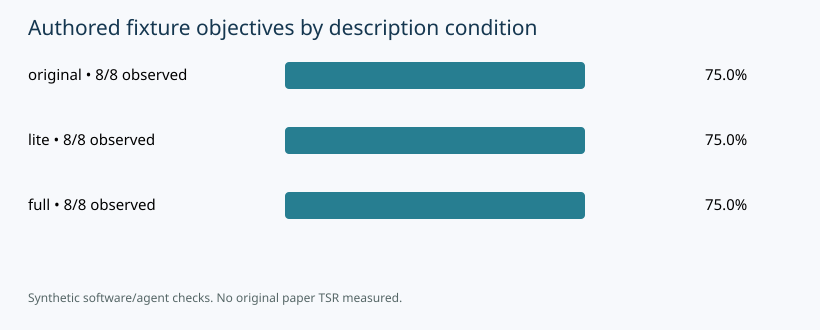

# Phase 2 status: INCOMPLETE

The automatic pipeline finished and produced a handover package. This is an independent, partial reimplementation. It is not the authors' released implementation or a completed quantitative reproduction.

16/24 task attempts completed in this run. These are authored fixture tasks, not the original 208 tasks. Consult results.json for actual outcomes and missing observations. A generated report or ZIP does not establish scientific completion.

## Outstanding essential evidence

- Original 52-tool/208-task release, labels, traces and exact prompts not recovered.
- Original generation models and fixed Gemini-3-Flash task agent replaced by explicitly named free local model.
- Python AST subset; TypeScript, unrestricted dynamic dispatch and proof of slicing equivalence unavailable.
- Full external MCP transport is gated by a validated immutable-image backend; the separate macOS boundary supports offline Python source observations only.
- Finite authored fixture observations and automated oracles do not establish original human-reviewed TSR.
- Q3 degraded-tool competition, Q4 seven original attacks and Q5 adaptive naming experiments lack authenticated experimental artifacts.

## Delivered implementation

Automatic source acquisition, conservative SliceMin, local-model DescGen with exact-source attribution and interface checks, iterative DynVer, a fixed task agent across original/lite/full, explicit fixture oracles, checkpoints, validation, reports and an integrity-indexed ZIP. Failed scientific stages are recorded; no replay substitutes for a failed model.


{'status': 'loaded_real_local_model',
 'selected': {'temperature': 0.0,
  'seed': 42,
  'max_input_tokens': 12288,
  'max_new_tokens': 1600,
  'max_generation_seconds': 180,
  'max_calls': 600,
  'debloat': True,
  'reasoning': 'provider_default',
  'id': 'qwen3-mlx-4b',
  'provider': 'local',
  'backend': 'mlx',
  'model_id': 'mlx-community/Qwen3-4B-Instruct-2507-4bit',
  'revision': '50d427756c6b1b2fe0c0a10f67fbda1fc8e82c1b',
  'estimated_weight_bytes': 2263022417,
  'minimum_available_ram_bytes': 3758096384,
  'device': 'metal',
  'substitution': 'Apple Silicon quantized local model; independent substitute, not paper models'},
 'task_agent': {'temperature': 0.0,
  'seed': 42,
  'max_input_tokens': 12288,
  'max_new_tokens': 1600,
  'max_generation_seconds': 180,
  'max_calls': 600,
  'debloat': True,
  'reasoning': 'provider_default',
  'id': 'qwen3-mlx-4b',
  'provider': 'local',
  'backend': 'mlx',
  'model_id': 'mlx-community/Qwen3-4B-Instruct-2507-4bit',
  'revision': '50d427756

In [5]:
RESULTS = json.loads((RUN/"results.json").read_text())
display([row for row in RESULTS["conditions"] if row["tool"]=="ALL"])
display(SVG(filename=str(RUN/"plots/fixture_objectives.svg")))
display(Markdown((RUN/"PHASE2_COMPLETION_REPORT.md").read_text()))
display(json.loads((RUN/"model_manifest.json").read_text()))

## 5 · Validate software and export the handover
Software checks are separate from scientific results. The archive is CRC-checked and every member is SHA-256-verified by the exporter. Model weights, caches, private PDFs and credentials are excluded.

In [6]:
print((RUN/"software_tests.txt").read_text()[-2500:])
tests=json.loads((RUN/"software_test_status.json").read_text())
if tests.get("returncode") != 0:
    raise RuntimeError("Software tests failed; inspect saved software_tests.txt")
display(json.loads((RUN/"validation_report.json").read_text()))
for path in [Path(LATEST["archive"]),Path(LATEST["checksum_file"]),RUN/"FINAL_PROJECT_COMPLETION_REPORT.md",RUN/"PHASE2_COMPLETION_REPORT.md",RUN/"PHASE3_HANDOVER.md",RUN/"EXPERIMENT_RESULTS.md",RUN/"results.json"]:
    display(FileLink(os.path.relpath(path,Path.cwd())))
print("Handover exported. Scientific completion status:",LATEST["phase2_scientific_complete"])

............................................................................................................................................................
----------------------------------------------------------------------
Ran 156 tests in 7.747s

OK



{'valid': True,
 'errors': [],
 'required_files': ['PHASE2_COMPLETION_REPORT.md',
  'PHASE3_HANDOVER.md',
  'METHODOLOGY.md',
  'DATASET_PROVENANCE.md',
  'EXPERIMENT_RESULTS.md',
  'LIMITATIONS_AND_REPRODUCIBILITY.md',
  'REPRODUCTION_INSTRUCTIONS.md',
  'FINAL_PROJECT_COMPLETION_REPORT.md',
  'results.json',
  'EXPERIMENT_MANIFEST.json',
  'dataset_manifest.json',
  'model_manifest.json',
  'prompt_manifest.json',
  'source_hashes.json',
  'config.json',
  'execution_traces.jsonl',
  'tool_verification.json',
  'acquisition_report.json',
  'environment.json',
  'installed_packages.txt',
  'metrics.csv',
  'description_comparisons.json'],
 'fixed_task_agent': True,
 'original_paper_TSR_computed': False,
 'phase2_complete': False,
 'scope': 'artifact/software consistency, not scientific efficacy',
 'scientific_stage_failures': 15}

/Users/macbramesha/Documents/Codex/2026-11-09/https-github-com-samarthramesha-trustdesc-reproduction-2/work/notebook-fresh/experiment/deliverables/automatic-93589e7e9672adf4a537/phase3_handover.zip

/Users/macbramesha/Documents/Codex/2026-11-09/https-github-com-samarthramesha-trustdesc-reproduction-2/work/notebook-fresh/experiment/deliverables/automatic-93589e7e9672adf4a537/phase3_handover.zip.sha256

/Users/macbramesha/Documents/Codex/2026-11-09/https-github-com-samarthramesha-trustdesc-reproduction-2/work/notebook-fresh/experiment/runs/automatic-93589e7e9672adf4a537/FINAL_PROJECT_COMPLETION_REPORT.md

/Users/macbramesha/Documents/Codex/2026-11-09/https-github-com-samarthramesha-trustdesc-reproduction-2/work/notebook-fresh/experiment/runs/automatic-93589e7e9672adf4a537/PHASE2_COMPLETION_REPORT.md

/Users/macbramesha/Documents/Codex/2026-11-09/https-github-com-samarthramesha-trustdesc-reproduction-2/work/notebook-fresh/experiment/runs/automatic-93589e7e9672adf4a537/PHASE3_HANDOVER.md

/Users/macbramesha/Documents/Codex/2026-11-09/https-github-com-samarthramesha-trustdesc-reproduction-2/work/notebook-fresh/experiment/runs/automatic-93589e7e9672adf4a537/EXPERIMENT_RESULTS.md

/Users/macbramesha/Documents/Codex/2026-11-09/https-github-com-samarthramesha-trustdesc-reproduction-2/work/notebook-fresh/experiment/runs/automatic-93589e7e9672adf4a537/results.json

Handover exported. Scientific completion status: False
